# ANALYSIS — sweep summary table

One row per `run_XXXX` under every sweep folder in `data/eigenbasis` (inside this repo),
reusing the loaders from `plot_energy_vs_iteration.ipynb`:

`vit shape [nlayers, ratio, nheads] || Nparams || (init_lr, final_lr, warmup) || (init_ds, final_ds, warmup) || final_relE || variance || N_iter || N_mc || symmetries`

plus `s/it`, run status, and the full sweep-folder name to copy/paste back into the
plotting notebook. The table is split into one section per **nlayers** (so the
shallow and deep ViTs are compared against their own kind, not against each
other), and within each section rows are sorted **worst to best**, so the best
`relE` in that depth is the bottom row.

**Where each number comes from**
- **vit shape** — `model.layers / ratio / heads` from the run's `config.json`
  (`d_model = ratio * heads`, as `run_2D_eigenbasis.py` derives it).
- **Nparams** — the `n_params = N` line `run_2D_eigenbasis.py` prints to
  `stdout.txt` once the `MCState` is built, i.e. `nk.jax.tree_size` of the actual
  parameter tree. Taken from the run rather than recomputed, so symmetrisation
  and the embedding mode are already folded in; `-` means the run never got far
  enough to print it.
- **lr / ds** — `optimizer.*`, in scientific notation; *warmup* is
  `lr_transition_steps` / `ds_transition_steps`, i.e. the number of steps the schedule
  takes to decay from the initial to the final value.
  Old Adam runs have no diagonal shift, so that cell reads `adam(b1,b2)` instead.
- **final_relE** — `|E - E0| / |E0|` on the **total** energy (scale-invariant, so
  per-site gives the same number), with `E` averaged over the last `TAIL_AVG`
  logged iterations to kill single-step MC noise. `E0` is the ED reference from
  `run.summary.json` when present, otherwise the manual per-site value in
  `E0_PER_SITE_REF` below (6x6 has no ED).
- **variance** — the energy variance NetKet logs as `Energy.Variance` (the
  σ² in the tqdm bar), averaged over the same trailing `TAIL_AVG` iterations.
  This is the total; the per-run detail block below also gives σ² per site.
  It is the zero-variance diagnostic, so it should fall along with `relE` — a run
  whose `relE` is low but whose variance is not has a wavefunction that is only
  accidentally close in energy.
- **N_iter** — last *global* iteration present in the merged `*.log` files
  (resubmissions continue the global count), shown as `reached/target`.
- **N_mc** — `sampler.N_SAMPLES`, matching `N_SAMPLES` in the driver. Runs
  predating that rename stored `sampler.MONTECARLO`, a multiplier against a
  hidden 2048, and are converted on load so old and new sweeps compare directly.
- **symmetries** — `symmetry.elements` / `spin_flip`; `off` = empty list,
  `off (legacy)` = run predates the `[symmetry]` block.
- **s/it** — median tqdm step time over the middle half of `stderr.txt`, so JIT
  compilation at the start and any stall at the end are excluded.

Just run all.

In [66]:
from pathlib import Path

# --- EDIT ME ---------------------------------------------------------------
# Same data-root discovery as the plotting notebook: "data/eigenbasis" sits in the repo root above the
# folder holding this notebook, so this works locally and on the RC cluster.
def _find_data_root(name="data/eigenbasis"):
    here = Path.cwd().resolve()
    for base in (here, *here.parents):
        cand = base / name
        if cand.is_dir():
            return cand
    raise FileNotFoundError(f"could not find a {name!r} directory at or above {here}")

DATA_ROOT = _find_data_root()
print("DATA_ROOT =", DATA_ROOT)

# Manual per-site reference energies, for systems where ED is skipped and
# run.summary.json therefore has E0 = null. Keyed by (L, J2).
E0_PER_SITE_REF = {
    (6, 0.0): -0.678872,    # 6x6, J2 = 0
}

# Number of trailing logged iterations averaged into the "final" energy and
# variance. 1 = literally the last point (noisier); 50 = last 50 steps.
TAIL_AVG = 50

# Row order WITHIN a section: "relE" puts the WORST relE first and the best in
# the bottom row (runs with no energy at all lead); "folder" is chronological,
# matching the directory listing.
SORT_BY = "relE"

# Field the table is sectioned on. "layers" gives one block per ViT depth;
# None puts every run in a single table.
SECTION_BY = "layers"

# Skip runs that produced no *.log at all (crashed before the first step /
# never submitted). False keeps them as rows with empty result columns.
HIDE_EMPTY = False

# NetKet logs the energy under this key.
QUANTITY = "Energy"
# ---------------------------------------------------------------------------

DATA_ROOT = /Users/ashilcusky/Documents/master/2D_data


In [67]:
import json
import re
import numpy as np
import matplotlib.pyplot as plt

## Loaders

`load_log` / `load_run_energy` are the same merge-every-`*.log`-by-global-iteration
routines as in `plot_energy_vs_iteration.ipynb` (resubmitted runs write
`run step NNNN.log` with global iteration numbers), trimmed to just the energy.

`iter_rate` scrapes the tqdm bar in `stderr.txt`, `load_n_params` the
`n_params = N` line in `stdout.txt`; `load_meta` resolves the config
from `manifest.json`, falling back to `config.json` and then to the sweep-level
`matrix.json` entry, which is the only source left for runs whose directory is
empty because the job never started.

In [68]:
def load_log(log_path):
    """One NetKet JsonLog .log -> (iters, mean_real, variance), or None.

    `Variance` is the sigma^2 NetKet shows in the tqdm bar; it sits next to
    `Mean` in the same block, so it costs nothing to carry along.
    """
    with open(log_path) as f:
        data = json.load(f)
    block = data.get(QUANTITY)
    if block is None:
        return None
    iters = np.asarray(block["iters"], dtype=float)

    def column(name):
        col = block.get(name)
        if col is None:
            return None
        if isinstance(col, dict) and "real" in col:  # complex -> real part
            col = col["real"]
        return np.asarray(col, dtype=float)

    mean = column("Mean")
    if mean is None:
        return None
    var = column("Variance")
    if var is None:
        var = np.full_like(mean, np.nan)
    return iters, mean, var


def load_run_energy(run_dir):
    """Merge every *.log in a run dir into one curve sorted by global iteration."""
    its, means, vars_ = [], [], []
    for lp in sorted(run_dir.glob("*.log")):
        try:
            loaded = load_log(lp)
        except Exception as e:
            print(f"   (skipped {run_dir.name}/{lp.name}: {e})")
            continue
        if loaded is None:
            continue
        its.append(loaded[0])
        means.append(loaded[1])
        vars_.append(loaded[2])
    if not its:
        return None
    it   = np.concatenate(its)
    mean = np.concatenate(means)
    var  = np.concatenate(vars_)
    order = np.argsort(it, kind="stable")
    it, mean, var = it[order], mean[order], var[order]
    seen = {}                                        # de-duplicate, keep last
    for pos, itv in enumerate(it):
        seen[float(itv)] = pos
    keep = np.array([seen[k] for k in sorted(seen)])
    return it[keep], mean[keep], var[keep]


_RATE = re.compile(r"(\d+(?:\.\d+)?)(s/it|it/s)")

def iter_rate(run_dir):
    """Median tqdm speed in it/s over the middle half of stderr.txt.

    tqdm writes '4.16s/it' or '1.23it/s' depending on which side of 1 s/step the
    run is on, and rewrites the bar with \r, so this splits on \r as well as \n.
    Taking the middle half drops the JIT-compilation steps at the start (tens of
    seconds each) and anything weird at the very end; resubmissions just restart
    the bar inside the same file, which the median absorbs.
    """
    p = run_dir / "stderr.txt"
    if not p.exists():
        return None
    rates = []
    with open(p, errors="replace") as f:
        for chunk in f:
            for line in chunk.replace("\r", "\n").split("\n"):
                m = _RATE.search(line)
                if not m:
                    continue
                v = float(m.group(1))
                if v == 0.0:
                    continue
                rates.append(v if m.group(2) == "it/s" else 1.0 / v)
    if not rates:
        return None
    a = np.asarray(rates)
    return float(np.median(a[len(a) // 4 : (3 * len(a)) // 4 or None]))


_NPARAMS = re.compile(r"n_params\s*=\s*(\d+)")

def load_n_params(run_dir):
    """Parameter count the driver prints to stdout.txt as 'n_params = N'.

    `run_2D_eigenbasis.py` reports `nk.jax.tree_size(vstate.parameters)` right
    after building the MCState, so this is the real count for the symmetrised
    model rather than a formula re-derived from [layers, ratio, heads].
    Resubmissions append to the same stdout.txt and rebuild an identical model,
    so the last match is as good as the first; None means the run died before
    the state existed (or has no stdout.txt at all).
    """
    p = run_dir / "stdout.txt"
    if not p.exists():
        return None
    found = None
    with open(p, errors="replace") as f:
        for line in f:
            m = _NPARAMS.search(line)
            if m:
                found = int(m.group(1))
    return found


def _matrix_entry(run_dir):
    """Sweep-level fallback: matrix.json holds every run's resolved config."""
    mx = run_dir.parent / "matrix.json"
    if not mx.exists():
        return None
    try:
        m = json.loads(mx.read_text())
        rid = int(run_dir.name.split("_")[-1])
    except Exception:
        return None
    for r in m.get("runs", []):
        if int(r.get("run_id", -1)) == rid:
            return {"config": r.get("config"),
                    "sweep_values": r.get("sweep_values") or {},
                    "git": (m.get("git_commit") or "")[:7]}
    return None


def load_meta(run_dir):
    """config / swept values / git / status / resubmission count for one run."""
    meta = {"config": None, "sweep_values": {}, "git": None,
            "status": None, "resubs": 0}

    man = run_dir / "manifest.json"
    if man.exists():
        m = json.loads(man.read_text())
        meta.update(config=m.get("config"),
                    sweep_values=m.get("sweep_values") or {},
                    git=(m.get("git_commit") or "")[:7],
                    status=m.get("status"),
                    resubs=len(m.get("resubmissions") or []))

    if meta["config"] is None:
        cj = run_dir / "config.json"
        if cj.exists():
            meta["config"] = json.loads(cj.read_text())

    if meta["config"] is None:                       # empty run dir
        fallback = _matrix_entry(run_dir)
        if fallback:
            meta["config"] = fallback["config"]
            meta["sweep_values"] = meta["sweep_values"] or fallback["sweep_values"]
            meta["git"] = meta["git"] or fallback["git"]

    if meta["status"] is None:                       # infer from marker files
        if (run_dir / "run.done").exists():
            meta["status"] = "done"
        elif (run_dir / "run.timeout").exists():
            meta["status"] = "timeout"
        elif any(run_dir.glob(".runinfo_*")):
            meta["status"] = "running?"
        elif not any(run_dir.iterdir()):
            meta["status"] = "empty"
    return meta

## Formatting helpers

Short labels for the C4v elements, and the `E0` lookup (ED first, manual
per-site reference second) shared by every row.

In [69]:
_SYM_SHORT = {"I": "I", "C4": "C4", "C2": "C2", "C4_3": "C4^3",
              "sigma_d": "s_d", "sigma_a": "s_a",
              "sigma_x": "s_x", "sigma_y": "s_y"}

def symmetry_str(cfg):
    """'off' / 'off (legacy)' / '|G|=4: I,C2,s_d,s_a' (+flip)."""
    symm = (cfg or {}).get("symmetry")
    if symm is None:
        return "off (legacy)"          # config predates the [symmetry] block
    els = list(symm.get("elements") or [])
    flip = bool(symm.get("spin_flip"))
    if not els and not flip:
        return "off"
    order = (len(els) or 1) * (2 if flip else 1)
    bits = ",".join(_SYM_SHORT.get(e, e) for e in els) or "-"
    return f"|G|={order}: {bits}" + (" +flip" if flip else "")


def ref_per_site(L, J2):
    """Manual per-site reference for (L, J2), tolerant on the J2 float."""
    if L is None or J2 is None:
        return None
    for (Lr, J2r), val in E0_PER_SITE_REF.items():
        if int(Lr) == int(L) and abs(float(J2r) - float(J2)) < 1e-9:
            return float(val)
    return None


def _sci(x, nd=1):
    """Scientific notation for a rate / shift: 5.0e-02, 1.0e-04, or '-'."""
    if x is None:
        return "-"
    return f"{float(x):.{nd}e}"


def _steps(x):
    """Warmup is a step count, so it stays a plain integer."""
    return "-" if x is None else str(int(x))


def lr_cell(opt):
    return f"({_sci(opt.get('initial_learning_rate'))}, " \
           f"{_sci(opt.get('final_learning_rate'))}, " \
           f"{_steps(opt.get('lr_transition_steps'))})"


def ds_cell(opt):
    """Diagonal shift schedule, or the Adam betas for the pre-SR runs."""
    if "initial_diagonal_shift" not in opt:
        if "b1" in opt:                              # betas are O(1), not rates
            return f"adam(b1={opt.get('b1'):g}, b2={opt.get('b2'):g})"
        return "-"
    return f"({_sci(opt.get('initial_diagonal_shift'))}, " \
           f"{_sci(opt.get('final_diagonal_shift'))}, " \
           f"{_steps(opt.get('ds_transition_steps'))})"

## Scan every sweep folder

In [70]:
def build_row(sweep_dir, run_dir):
    meta = load_meta(run_dir)
    cfg  = meta["config"] or {}
    sysc = cfg.get("system", {})
    mdl  = cfg.get("model", {})
    opt  = cfg.get("optimizer", {})
    smp  = cfg.get("sampler", {})
    dist = cfg.get("distribution", {})

    L, J2 = sysc.get("L"), sysc.get("J2")
    n_sites = int(L) ** 2 if L is not None else None

    # reference energy: ED from summary.json if it exists, else the manual value
    E0_total, E0_per_site, E0_src = None, None, None
    summ = run_dir / "run.summary.json"
    if summ.exists():
        try:
            s = json.loads(summ.read_text())
            if s.get("E0") is not None:
                E0_total = float(s["E0"])
                E0_src = "ED"
                if n_sites:
                    E0_per_site = E0_total / n_sites
        except Exception:
            pass
    if E0_total is None:
        E0_per_site = ref_per_site(L, J2)
        if E0_per_site is not None and n_sites:
            E0_total, E0_src = E0_per_site * n_sites, "ref"

    # energy history (kept whole: the plotting cell below reuses it)
    n_iter = E_final = E_per_site = relE = var = var_per_site = None
    it = mean = variance = None
    loaded = load_run_energy(run_dir)
    if loaded is not None:
        it, mean, variance = loaded
        tail = max(1, TAIL_AVG)
        n_iter = int(it[-1])
        E_final = float(np.mean(mean[-tail:]))
        v = float(np.nanmean(variance[-tail:]))
        if not np.isnan(v):
            var = v
            if n_sites:
                var_per_site = var / n_sites
        if n_sites:
            E_per_site = E_final / n_sites
        if E0_total:
            relE = abs(E_final - E0_total) / abs(E0_total)

    # N_SAMPLES is the sample count itself. Older runs stored MONTECARLO,
    # a multiplier against a hidden 2048 -- convert those so historical
    # sweeps stay comparable with current ones.
    n_mc = smp.get("N_SAMPLES")
    if n_mc is None:
        mc = smp.get("MONTECARLO")
        n_mc = int(2048 * mc) if mc else None
    ratio, heads = mdl.get("ratio"), mdl.get("heads")
    d_model = mdl.get("d_model")
    if d_model is None and ratio is not None and heads is not None:
        d_model = int(ratio) * int(heads)

    return {
        "folder": sweep_dir.name, "run": run_dir.name, "run_dir": run_dir,
        "layers": mdl.get("layers"), "ratio": ratio, "heads": heads,
        "d_model": d_model, "n_params": load_n_params(run_dir),
        "lr": lr_cell(opt), "ds": ds_cell(opt),
        "relE": relE, "E_final": E_final, "E_per_site": E_per_site,
        "var": var, "var_per_site": var_per_site,
        "iters": it, "mean": mean, "variance": variance,
        "E0": E0_total, "E0_per_site": E0_per_site, "E0_src": E0_src,
        "n_iter": n_iter, "n_target": mdl.get("iter"),
        "n_mc": n_mc,
        "sym": symmetry_str(cfg),
        "it_s": iter_rate(run_dir),
        "status": meta["status"], "git": meta["git"], "resubs": meta["resubs"],
        "sweep_values": meta["sweep_values"],
        "L": L, "J2": J2, "n_sites": n_sites,
        "alpha": dist.get("alpha"), "auto_alpha": dist.get("auto_alpha"),
        "embedding": mdl.get("embedding"), "attention": mdl.get("attention_mode"),
        "chains": smp.get("chains"), "discard": smp.get("discard_per_chain"),
    }


rows = []
for sweep_dir in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir()):
    run_dirs = sorted(sweep_dir.glob("run_*"))
    if not run_dirs:
        print(f"!! no run_* subfolders under {sweep_dir.name}")
        continue
    for run_dir in run_dirs:
        rows.append(build_row(sweep_dir, run_dir))

if HIDE_EMPTY:
    rows = [r for r in rows if r["n_iter"] is not None]
if SORT_BY == "relE":
    # worst first, best last: runs with no relE lead, then descending relE.
    rows.sort(key=lambda r: (0, 0.0) if r["relE"] is None else (1, -r["relE"]))

n_noref = sum(1 for r in rows if r["E0"] is None)
print(f"{len(rows)} run(s) across "
      f"{len({r['folder'] for r in rows})} sweep folder(s)"
      + (f"; {n_noref} with no reference E0 (blank relE)" if n_noref else ""))

21 run(s) across 15 sweep folder(s)


## The table

`N_iter` is `reached/target`; a `*` on the status marks resubmitted runs.

In [71]:
def vit_cell(r):
    if r["layers"] is None:
        return "-"
    return f"[{r['layers']}, {r['ratio']}, {r['heads']}]"

def nparams_cell(r):
    return "-" if r["n_params"] is None else f"{r['n_params']:,}"

def relE_cell(r):
    return "-" if r["relE"] is None else f"{r['relE']:.2e}"

def iters_cell(r):
    if r["n_iter"] is None:
        return f"-/{r['n_target']}" if r["n_target"] else "-"
    return f"{r['n_iter']}/{r['n_target']}"

def var_cell(r):
    return "-" if r["var"] is None else f"{r['var']:.3e}"

def rate_cell(r):
    """Step time in s/it, which is the side of 1 s/step every run here is on."""
    if not r["it_s"]:
        return "-"
    return f"{1 / r['it_s']:.2f}"

def status_cell(r):
    s = r["status"] or "?"
    return s + ("*" if r["resubs"] else "")

COLUMNS = [
    ("vit [nl,ratio,nh]",        vit_cell),
    ("Nparams",                  nparams_cell),
    ("(lr0, lr1, warmup)",       lambda r: r["lr"]),
    ("(ds0, ds1, warmup)",       lambda r: r["ds"]),
    ("final_relE",               relE_cell),
    ("variance",                 var_cell),
    ("N_iter",                   iters_cell),
    ("N_mc",                     lambda r: str(r["n_mc"] or "-")),
    ("symmetries",               lambda r: r["sym"]),
    ("s/it",                     rate_cell),
    ("status",                   status_cell),
    ("folder",                   lambda r: r["folder"]),
    ("run",                      lambda r: r["run"]),
]


def sections(rows, key=None):
    """[(section label, rows)], one per distinct value of `key`.

    Sections are ordered by the value itself (2 layers before 8), with any run
    whose value is missing collected last so it never hides in the middle.
    """
    key = SECTION_BY if key is None else key
    if not key:
        return [(None, rows)]
    groups = {}
    for r in rows:
        groups.setdefault(r.get(key), []).append(r)
    known = sorted((k for k in groups if k is not None))
    return ([(f"{key} = {k}", groups[k]) for k in known]
            + ([(f"{key} = ?", groups[None])] if None in groups else []))


def col_widths(rows, columns=COLUMNS):
    """Widths over ALL rows, so every section stays column-aligned."""
    body = [[fn(r) for _, fn in columns] for r in rows]
    return [max(len(h), *(len(b[i]) for b in body)) if body else len(h)
            for i, (h, _) in enumerate(columns)]


def render(rows, columns=COLUMNS, width=None):
    width = col_widths(rows, columns) if width is None else width
    header = " | ".join(h.ljust(w) for (h, _), w in zip(columns, width))
    sep = "-+-".join("-" * w for w in width)
    out = [header, sep]
    prev = None
    for r in rows:
        # rule between sweeps, but only when rows are still in folder order
        if SORT_BY == "folder" and prev is not None and r["folder"] != prev:
            out.append(sep)
        prev = r["folder"]
        out.append(" | ".join(fn(r).ljust(w) for (_, fn), w in zip(columns, width)))
    return "\n".join(out)


width = col_widths(rows)                 # shared, so sections line up
for label, block in sections(rows):
    if label is not None:
        print(f"\n=== {label}   ({len(block)} run(s)) ===")
    print(render(block, width=width))


=== layers = 2   (15 run(s)) ===
vit [nl,ratio,nh] | (lr0, lr1, warmup)       | (ds0, ds1, warmup)       | final_relE | variance  | N_iter      | N_mc | symmetries          | s/it  | status               | folder                              | run     
------------------+--------------------------+--------------------------+------------+-----------+-------------+------+---------------------+-------+----------------------+-------------------------------------+---------
[2, 3, 20]        | (1.0e-03, 1.0e-04, 1200) | adam(b1=0.9, b2=0.999)   | -          | -         | -/10000     | 8192 | off (legacy)        | -     | failed               | 2026-09-01_13-38-15G5810413P2340655 | run_0000
[2, 6, 12]        | (5.0e-02, 2.0e-02, 400)  | (1.0e-03, 1.0e-03, 400)  | -          | -         | -/10000     | 8192 | off (legacy)        | -     | crashed_before_setup | 2026-09-21_09-50-17G6f20533P344880  | run_0000
[2, 6, 12]        | (5.0e-02, 2.0e-02, 400)  | (1.0e-03, 1.0e-03, 400)  | -          |

## Same table, rendered

Easier to scan in the notebook; the `folder` column is still plain text, so
selecting it copies cleanly into `SWEEP_FOLDERS` in the plotting notebook.

In [72]:
from IPython.display import HTML, display
from html import escape

def to_html(rows, columns=COLUMNS):
    th = "".join(f"<th style='text-align:left;padding:3px 9px'>{escape(h)}</th>"
                 for h, _ in columns)
    trs = []
    for label, block in sections(rows):
        if label is not None:                        # section banner row
            trs.append(
                f"<tr><td colspan='{len(columns)}' style='padding:9px 9px 3px;"
                "border-top:1px solid #999;font-weight:600'>"
                f"{escape(label)} &nbsp;<span style='font-weight:400;color:#666'>"
                f"({len(block)} run(s))</span></td></tr>")
        for i, r in enumerate(block):
            bg = "#fafafa" if i % 2 else "transparent"
            tds = []
            for h, fn in columns:
                val = escape(fn(r))
                mono = "font-family:monospace" if h in ("folder", "run") else ""
                tds.append(f"<td style='padding:3px 9px;white-space:nowrap;{mono}'>{val}</td>")
            trs.append(f"<tr style='background:{bg}'>" + "".join(tds) + "</tr>")
    return HTML("<table style='border-collapse:collapse;font-size:12px'>"
                f"<thead><tr style='border-bottom:1px solid #999'>{th}</tr></thead>"
                f"<tbody>{''.join(trs)}</tbody></table>")

display(to_html(rows))

## Best runs by relative error

Top 5 per section, best last.

In [73]:
for label, block in sections(rows):
    if label is not None:
        print(f"=== {label} ===")
    ranked = sorted((r for r in block if r["relE"] is not None),
                    key=lambda r: r["relE"])[:5]
    for r in reversed(ranked):                 # best at the bottom
        print(f"{r['relE']:.2e}  var={var_cell(r)}  {vit_cell(r):<14} {r['sym']:<22} "
              f"E/site={r['E_per_site']:.6f}  {iters_cell(r):>12}  "
              f"{rate_cell(r):>6} s/it  {r['folder']}/{r['run']}")
    print()

=== layers = 2 ===
7.61e-03  var=3.649e-01  [2, 6, 12]     off                    E/site=-0.673708    3271/20000    4.21 s/it  2026-09-23_11-46-30G8bc0647P2417599/run_0001
7.24e-03  var=2.430e-01  [2, 6, 12]     off                    E/site=-0.673955    3306/20000    4.17 s/it  2026-09-23_11-46-30G8bc0647P2417599/run_0000
4.88e-03  var=1.941e-01  [2, 6, 12]     off (legacy)           E/site=-0.675560    9999/10000    3.59 s/it  2026-09-17_18-22-55G86bfd8fP557666/run_0000
3.34e-03  var=1.572e-01  [2, 6, 12]     off                    E/site=-0.676608    9999/10000    4.15 s/it  2026-09-21_12-33-47G6f5192bP3563991/run_0000
2.04e-03  var=6.721e-02  [2, 6, 12]     |G|=4: I,C2,s_d,s_a    E/site=-0.677487    9999/10000    6.46 s/it  2026-09-21_12-38-57G7f7a81dP3661511/run_0000

=== layers = 8 ===
5.01e-03  var=1.754e-01  [8, 6, 12]     off (legacy)           E/site=-0.675471    8382/10000   11.48 s/it  2026-09-15_15-32-08Gb64b4e9P2091703/run_0000
1.89e-03  var=9.693e-02  [8, 6, 12]     off 

## Energy and relative error vs. iteration

The two panels share an x-axis: the **total energy** on top (with the reference
`E0` as the dotted line) and **|E - E0| / |E0|** on a log scale below. Relative
error is computed on the totals, so it is the same curve either way; set
`PLOT_PER_SITE = True` to switch the top panel to `<H>/N`.

Both y-windows default to `"auto"`, fitted to the converged tail of the selected
runs — the first few hundred iterations fall an order of magnitude, so on a full
autoscale the part you actually care about is a flat line against the reference.
The window holds the last `ZOOM_TAIL` of each curve between its 1st and 99th
percentile (so one MC spike cannot blow it open), keeps `E0` in frame, and adds
`ZOOM_PAD` headroom. Set either `YLIM_*` to an explicit tuple, or to `None` for
plain autoscaling.

By default this draws the `N_PLOT` runs with the lowest `final_relE` — the bottom
rows of the table above. Put explicit `"folder/run_0000"` strings in `PLOT_RUNS`
to override that and compare whichever runs you like.

**Depth reads as colour family**: `nlayers = 2` runs are blues drawn solid,
`nlayers = 8` runs are oranges drawn dashed, and the runs inside one depth step
from dark to light. The legend is grouped the same way, and each curve is
labelled at its right-hand end in the relE panel (`MM-DD/run`) so identity never
rests on colour alone.

Single MC steps are noisy at this scale, so the raw trace is drawn faint and a
rolling mean of width `SMOOTH` is drawn on top; set `SMOOTH = 0` for raw only.

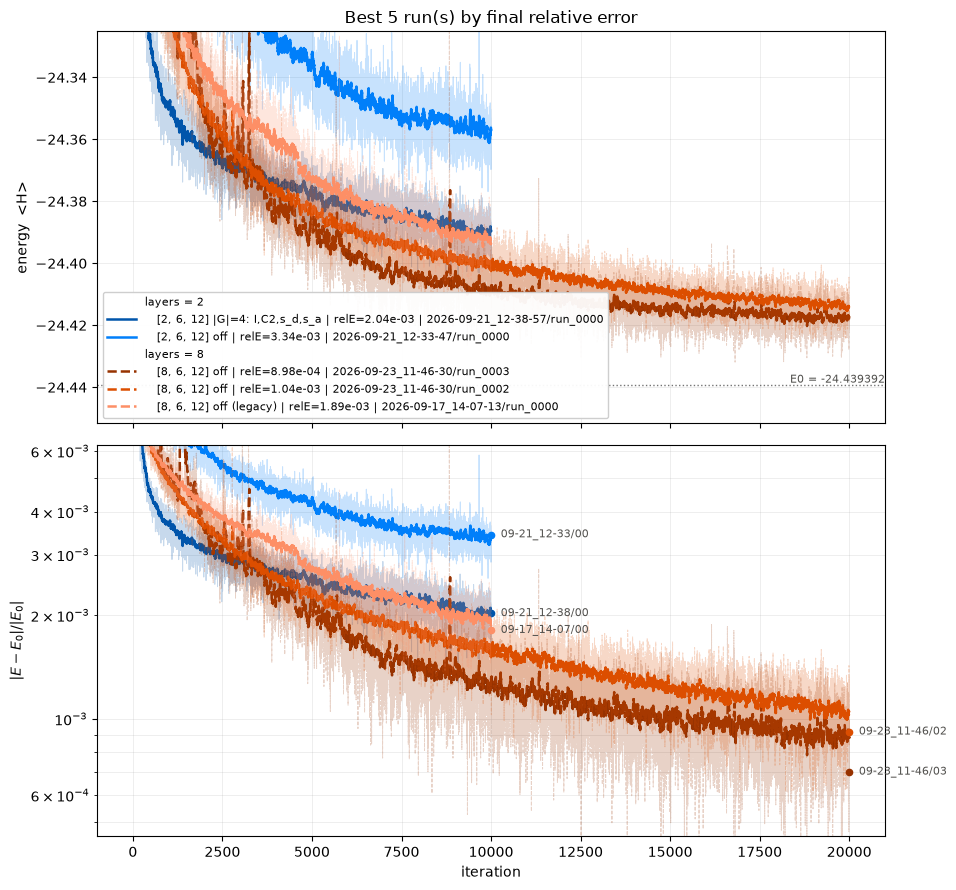

In [74]:
# --- EDIT ME ---------------------------------------------------------------
N_PLOT = 5             # how many of the best-relE runs to draw
PLOT_RUNS = []         # e.g. ["2026-09-21_12-38-57G7f7a81dP3661511/run_0000"];
                       # non-empty overrides N_PLOT
PLOT_PER_SITE = False  # False = total energy <H>; True = per site <H>/N
SMOOTH = 25            # rolling-mean window for the solid curve; 0 or 1 = raw
GROUP_BY = "layers"    # field whose value picks the colour family; None = one family
XLIM = None            # e.g. (0, 4000)

# Y windows. "auto" fits the converged tail (see ZOOM_*) so the plateau fills the
# panel instead of being squashed against the reference by the initial descent;
# None autoscales the whole curve; a tuple is used as given.
YLIM_ENERGY = "auto"   # e.g. (-24.46, -24.28) for totals
YLIM_RELE = "auto"     # e.g. (8e-4, 2e-2)
ZOOM_TAIL = 0.5        # fraction of each curve, from the end, the window must hold
ZOOM_PAD = 0.12        # headroom, as a fraction of the fitted span (energy panel)
ZOOM_PAD_LOG = 1.5     # headroom as a multiplicative factor (relE panel)
# ---------------------------------------------------------------------------

# One colour family per group, stepped dark -> light for the runs inside it, plus
# a line style per family so the grouping survives greyscale and colour-blindness.
#
# These six steps were run through the data-viz palette validator on a white
# surface with every pair in play: lightness band and chroma floor pass, worst
# CVD separation dE 13.1 (protan), worst normal-vision dE 15.6 -- clear of the
# >=15 floor. THREE steps per family is the validated size; a fourth step puts a
# within-family pair under the floor, so the cell warns rather than inventing one.
# The lightest step of each family sits under 3:1 against white, which is why
# every curve also gets a direct end-label instead of relying on colour alone.
FAMILIES = [
    {"name": "blue",   "steps": ["#0055ab", "#007ffa", "#7ab4ff"], "ls": "-"},
    {"name": "orange", "steps": ["#973200", "#dc4e00", "#fd8f66"], "ls": "--"},
]
INK = "#52514e"        # labels wear text ink; the marker beside them carries identity


def pick_runs(rows):
    """Explicit PLOT_RUNS if given, else the N_PLOT lowest-relE runs."""
    if PLOT_RUNS:
        want = {s.strip("/ ") for s in PLOT_RUNS}
        chosen = [r for r in rows if f"{r['folder']}/{r['run']}" in want]
        for missing in sorted(want - {f"{r['folder']}/{r['run']}" for r in chosen}):
            print(f"!! no such run: {missing}")
        return chosen
    return sorted((r for r in rows if r["relE"] is not None),
                  key=lambda r: r["relE"])[:N_PLOT]


def plot_label(r):
    return (f"{vit_cell(r)} {r['sym']} | relE={relE_cell(r)} | "
            f"{r['folder'][:19]}/{r['run']}")


def make_tags(sel):
    """Shortest end-of-curve labels that are still unique across `sel`.

    'MM-DD/NN' is enough most of the time, but two sweeps launched on the same
    day would collide, so this widens the timestamp until every tag differs.
    """
    def tag(r, n):
        return f"{r['folder'][5:5 + n]}/{r['run'].split('_')[-1][-2:]}"
    for n in (5, 11, 19):            # MM-DD | MM-DD_HH-MM | full timestamp
        tags = {id(r): tag(r, n) for r in sel}
        if len(set(tags.values())) == len(sel):
            return tags
    return {id(r): f"{r['folder'][:19]}/{r['run']}" for r in sel}


def smooth(x, y, w):
    """Rolling mean, with x trimmed to match; a no-op for short curves."""
    if w and w > 1 and y.size > w:
        return x[w - 1:], np.convolve(y, np.ones(w) / w, mode="valid")
    return x, y


def zoom_span(tails):
    """(low, high) covering the converged tails, robust to single-step spikes."""
    if not tails:
        return None, None
    cat = np.concatenate(tails)
    return float(np.percentile(cat, 1)), float(np.percentile(cat, 99))


def place_end_labels(ax, ends, min_px=12):
    """Annotate each curve's last point, nudged apart so labels never overlap.

    Runs that converge to similar relE end within a few pixels of each other, so
    this walks them in display order and pushes each one up to `min_px` clear of
    the one below. Call it after the layout is final -- the transform it reads is
    only correct once the axes have been drawn at their final size.
    """
    if not ends:
        return
    fig = ax.figure
    fig.canvas.draw()
    rows = sorted((ax.transData.transform((x, y))[1], x, y, tag)
                  for x, y, tag in ends)
    last = -np.inf
    for y_disp, x, y, tag in rows:
        y_new = max(y_disp, last + min_px)
        last = y_new
        ax.annotate(tag, xy=(x, y),
                    xytext=(7, (y_new - y_disp) * 72 / fig.dpi),
                    textcoords="offset points", fontsize=8, va="center",
                    color=INK)


def group_styles(sel):
    """[(group value, [runs])] plus run -> (colour, linestyle).

    Groups are ordered by their value, so nlayers=2 always takes the first
    family and nlayers=8 the second no matter which runs got selected.
    """
    if not GROUP_BY:
        blocks = [(None, sel)]
    else:
        vals = sorted({r.get(GROUP_BY) for r in sel},
                      key=lambda g: (g is None, g))
        blocks = [(g, [r for r in sel if r.get(GROUP_BY) == g]) for g in vals]
    if len(blocks) > len(FAMILIES):
        print(f"!! {len(blocks)} groups but only {len(FAMILIES)} colour families "
              f"- add a validated family or set GROUP_BY = None")
    style = {}
    for gi, (g, members) in enumerate(blocks):
        fam = FAMILIES[gi % len(FAMILIES)]
        if len(members) > len(fam["steps"]):
            print(f"!! {len(members)} runs with {GROUP_BY}={g}, but the "
                  f"{fam['name']} family only has {len(fam['steps'])} validated "
                  f"steps - lower N_PLOT or facet instead")
        for mi, r in enumerate(members):
            style[id(r)] = (fam["steps"][mi % len(fam["steps"])], fam["ls"])
    return blocks, style


sel = [r for r in pick_runs(rows) if r["iters"] is not None]
if not sel:
    print("nothing to plot: no selected run has an energy history")
else:
    from matplotlib.lines import Line2D

    blocks, style = group_styles(sel)
    tags = make_tags(sel)
    fig, (ax_e, ax_r) = plt.subplots(2, 1, figsize=(10, 9), sharex=True)
    refs, handles, ends = {}, [], []
    tail_e, tail_r = [], []

    for g, members in blocks:
        if GROUP_BY:                                 # group header in the legend
            handles.append(Line2D([], [], color="none",
                                  label=f"{GROUP_BY} = {g}"))
        for r in members:
            colour, ls = style[id(r)]
            it, mean = r["iters"], r["mean"]
            n_sites = r["n_sites"] if (PLOT_PER_SITE and r["n_sites"]) else 1
            y = mean / n_sites

            # raw trace faint, rolling mean on top, same colour and style
            ax_e.plot(it, y, lw=0.7, alpha=0.22, color=colour, ls=ls)
            tail_e.append(y[int(len(y) * (1 - ZOOM_TAIL)):])
            xs, ys = smooth(it, y, SMOOTH)
            ax_e.plot(xs, ys, lw=1.8, color=colour, ls=ls)
            handles.append(Line2D([], [], color=colour, ls=ls, lw=1.8,
                                  label=("   " if GROUP_BY else "") + plot_label(r)))

            if r["E0"] is None:
                print(f"   (no reference E0, skipped in the relE panel: "
                      f"{r['folder']}/{r['run']})")
                continue
            rel = np.abs(mean - r["E0"]) / abs(r["E0"])
            ax_r.plot(it, rel, lw=0.7, alpha=0.22, color=colour, ls=ls)
            tail_r.append(rel[int(len(rel) * (1 - ZOOM_TAIL)):])
            xs, rs = smooth(it, rel, SMOOTH)
            ax_r.plot(xs, rs, lw=1.8, color=colour, ls=ls)

            # direct label: coloured dot carries identity, text stays in ink.
            # Placed after layout, below, so converged curves do not stack their
            # labels on top of each other.
            ax_r.plot([it[-1]], [rel[-1]], marker="o", ms=4.5, color=colour)
            ends.append((it[-1], rel[-1], tags[id(r)]))

            e0 = r["E0_per_site"] if (PLOT_PER_SITE and r["n_sites"]) else r["E0"]
            if e0 is not None:
                refs[round(e0, 8)] = (r["E0"], r["E0_per_site"], r["E0_src"])

    # dotted, so it never reads as one of the dashed group's curves
    for e0, (tot, per_site, src) in sorted(refs.items()):
        ax_e.axhline(e0, ls=":", color="0.45", lw=1)
        tag = "ED" if src == "ED" else "ref"
        txt = (f"E0/site = {per_site:.6f}   (total {tot:.6f}, {tag})"
               if PLOT_PER_SITE and per_site is not None
               else f"E0 = {tot:.6f}")
        ax_e.annotate(txt, xy=(1.0, e0), xycoords=("axes fraction", "data"),
                      ha="right", va="bottom", fontsize=8, color=INK)

    ax_e.set_ylabel("energy per site  <H>/N" if PLOT_PER_SITE else "energy  <H>")
    ax_e.set_title(f"{len(sel)} selected run(s)" if PLOT_RUNS else
                   f"Best {len(sel)} run(s) by final relative error")
    if YLIM_ENERGY == "auto":
        # keep the reference line in frame; percentiles so one MC spike in the
        # tail cannot blow the window open
        lo, hi = zoom_span(tail_e)
        if lo is not None:
            lo = min([lo] + list(refs))
            hi = max([hi] + list(refs))
            pad = ZOOM_PAD * (hi - lo or abs(hi) * 1e-3)
            ax_e.set_ylim(lo - pad, hi + pad)
    elif YLIM_ENERGY is not None:
        ax_e.set_ylim(*YLIM_ENERGY)
    ax_e.grid(alpha=0.25, lw=0.6)
    ax_e.set_axisbelow(True)
    ax_e.legend(handles=handles, fontsize=8, loc="lower left",
                handlelength=2.6, framealpha=0.95)

    ax_r.set_yscale("log")
    ax_r.set_xlabel("iteration")
    ax_r.set_ylabel(r"$|E - E_0| / |E_0|$")
    ax_r.grid(alpha=0.25, lw=0.6, which="both")
    ax_r.set_axisbelow(True)
    if YLIM_RELE == "auto":
        lo, hi = zoom_span(tail_r)
        if lo is not None and lo > 0:
            ax_r.set_ylim(lo / ZOOM_PAD_LOG, hi * ZOOM_PAD_LOG)
    elif YLIM_RELE is not None:
        ax_r.set_ylim(*YLIM_RELE)
    ax_r.margins(x=0.08)                             # room for the end labels
    if XLIM is not None:
        ax_r.set_xlim(*XLIM)

    fig.tight_layout()
    if ends:
        fig.subplots_adjust(right=0.89)              # gutter for the end labels
    place_end_labels(ax_r, ends)
    plt.show()

## Per-run detail

Everything the summary table leaves out: swept values, importance-sampling
settings, embedding / attention mode, sampler shape, git commit, and the
reference energy each `relE` was measured against.

In [ ]:
for label, block in sections(rows):
  if label is not None:
      print(f"{'=' * 70}\n{label}\n{'=' * 70}\n")
  for r in block:
    sweep = " ".join(f"{k.split('.')[-1]}={v}" for k, v in (r["sweep_values"] or {}).items())
    print(f"{r['folder']}/{r['run']}  [{r['git'] or '-'}]  {status_cell(r)}")
    print(f"    system     L={r['L']} J2={r['J2']} ({r['n_sites']} sites)")
    print(f"    model      layers={r['layers']} ratio={r['ratio']} heads={r['heads']} "
          f"d_model={r['d_model']} attention={r['attention']} embedding={r['embedding']}")
    print(f"    sampler    N_mc={r['n_mc']} chains={r['chains']} discard/chain={r['discard']}")
    print(f"    sampling   alpha={r['alpha']} auto_alpha={r['auto_alpha']}")
    print(f"    optimizer  lr={r['lr']}  ds={r['ds']}")
    print(f"    symmetry   {r['sym']}")
    if r["E_final"] is not None:
        e0 = "-" if r["E0"] is None else f"{r['E0']:.6f} ({r['E0_src']})"
        print(f"    energy     E={r['E_final']:.6f} (mean of last {TAIL_AVG}) "
              f"E/site={r['E_per_site']:.6f}  E0={e0}  relE={relE_cell(r)}")
        if r["var"] is not None:
            print(f"    variance   sigma^2={r['var']:.4e}"
                  + (f"  per site={r['var_per_site']:.4e}"
                     if r["var_per_site"] is not None else ""))
    else:
        print("    energy     no *.log written")
    print(f"    progress   {iters_cell(r)} iters at {rate_cell(r)} s/it"
          + (f", {r['resubs']} resubmission(s)" if r["resubs"] else ""))
    if sweep:
        print(f"    swept      {sweep}")
    print()

## Export

Writes `analysis_table.csv` next to this notebook.

In [ ]:
import csv

CSV_PATH = Path.cwd() / "analysis_table.csv"
FIELDS = ["folder", "run", "layers", "ratio", "heads", "d_model", "n_params",
          "lr", "ds", "relE", "var", "var_per_site",
          "E_final", "E_per_site", "E0", "E0_src",
          "n_iter", "n_target", "n_mc", "sym", "it_s", "status", "resubs",
          "git", "L", "J2", "alpha", "auto_alpha", "embedding", "attention",
          "chains", "discard"]

with open(CSV_PATH, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=FIELDS, extrasaction="ignore")
    w.writeheader()
    for r in rows:
        w.writerow(r)

print(f"wrote {len(rows)} rows -> {CSV_PATH}")